# Sistem Rekomendasi Berbasis Popularitas (Popularity-Based Recommender)

Notebook ini berisi implementasi empat pendekatan dasar untuk menyusun peringkat rekomendasi item berdasarkan data interaksi pengguna:

1. **Most Popular**: Berdasarkan jumlah interaksi terbanyak.
2. **Average Rating**: Berdasarkan nilai rata-rata ulasan tertinggi.
3. **Weighted Rating**: Menggunakan _Bayesian Average_ untuk mencegah bias pada item dengan sedikit ulasan.
4. **Time-Decay Popularity**: Memberikan bobot lebih besar pada interaksi yang paling baru (_trending_).


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## 1. Persiapan Dataset

Membuat dataset dummy berisi riwayat interaksi pengguna (`userId`), item (`itemId`), skor penilaian (`rating`), dan waktu transaksi (`timestamp`).


In [2]:
# Membuat dictionary data interaksi pengguna
data = {
  'userId': [
    1, 1, 1, 2, 2, 2,
    3, 3, 3, 4, 4, 5,
    5, 5, 6, 6, 7, 7,
  ],
  'itemId': [
    'A', 'B', 'C', 'A', 'B', 'D',
    'A', 'C', 'D', 'A', 'B', 'A',
    'C', 'E', 'B', 'D', 'A', 'E',
  ],
  'rating': [
    5, 4, 3, 4, 5, 3,
    5, 4, 2, 4, 4, 5,
    3, 5, 5, 4, 5, 4,
  ],
  'timestamp': [
    '2026-11-01', '2026-11-02', '2026-11-03',
    '2026-11-04', '2026-11-05', '2026-11-06',
    '2026-11-07', '2026-11-08', '2026-11-09',
    '2026-11-10', '2026-11-11', '2026-11-12',
    '2026-11-13', '2026-11-14', '2026-11-14',
    '2026-11-14', '2026-11-15', '2026-11-15',
  ],
}

# Konversi dictionary menjadi DataFrame pandas
df = pd.DataFrame(data)

# Ubah kolom timestamp dari string menjadi tipe datetime agar bisa dihitung selisih harinya
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Tampilkan 5 baris pertama untuk memastikan data sesuai
df.head()

,userId,itemId,rating,timestamp
0,1,A,5,2026-11-01
1,1,B,4,2026-11-02
2,1,C,3,2026-11-03
3,2,A,4,2026-11-04
4,2,B,5,2026-11-05


## 2. Fungsi Rekomendasi

### A. Most Popular (Jumlah Interaksi Terbanyak)

Menghitung jumlah interaksi pengguna terhadap setiap item tanpa mempertimbangkan nilai rating yang diberikan.

**Notasi Matematika:**
$$\text{Popularity}(i) = |I_i|$$

- $I_i$: Himpunan seluruh interaksi yang terjadi pada item $i$.
- $|I_i|$: Jumlah total interaksi untuk item $i$.

**Contoh Sederhana:**
Misalkan **Item A** diklik/dibeli sebanyak **6 kali**, sedangkan **Item B** hanya **4 kali**. Maka skor popularitas Item A adalah **6** dan Item B adalah **4**, sehingga Item A berada di peringkat lebih atas.

**Kelebihan & Kekurangan:**

- **Kelebihan:** Sangat sederhana, cepat dihitung, dan tidak membutuhkan data eksplisit seperti skor rating (cukup data klik atau kunjungan).
- **Kekurangan:** Mengabaikan kualitas item (produk dengan banyak ulasan buruk tetap dianggap populer) dan cenderung menciptakan efek _rich-get-richer_ (item lama terus mendominasi sementara item baru sulit naik).


In [3]:
def mostPopular(df: pd.DataFrame, topN: int = 10) -> pd.DataFrame:
  """
  Mengurutkan item berdasarkan jumlah interaksi terbanyak.

  Args:
      df (pd.DataFrame): DataFrame yang memiliki kolom 'itemId'.
      topN (int, optional): Jumlah item teratas yang ingin ditampilkan. Default 10.

  Returns:
      pd.DataFrame: Tabel berisi 'itemId' dan 'interactionCount' yang sudah terurut.
  """
  # Kelompokkan berdasarkan itemId, hitung jumlah barisnya, lalu urutkan dari terbesar
  popularity = (
    df.groupby('itemId')
    .size()
    .nlargest(topN)
    .reset_index(name='interactionCount')
  )

  # Ambil N baris teratas dan rapikan nomor indeksnya
  return popularity

### B. Average Rating (Rata-Rata Rating Tertinggi)

Mengurutkan item berdasarkan skor rata-rata rating yang diberikan oleh pengguna.

**Notasi Matematika:**
$$\bar{R}_i = \frac{1}{v_i} \sum_{u \in U_i} r_{u,i}$$

- $\bar{R}_i$: Rata-rata rating untuk item $i$.
- $v_i$: Jumlah total pengguna yang memberikan rating pada item $i$.
- $r_{u,i}$: Nilai rating yang diberikan oleh pengguna $u$ untuk item $i$.
- $U_i$	Himpunan pengguna yang memberikan rating pada item $i$.

**Contoh Sederhana:**
Misalkan **Item E** mendapatkan 2 ulasan dengan nilai **5** dan **4**.
$$\bar{R}_E = \frac{5 + 4}{2} = 4.5$$
Maka skor rata-rata Item E adalah **4.5**.

**Kelebihan & Kekurangan:**

- **Kelebihan:** Mencerminkan tingkat kepuasan dan kualitas item secara langsung berdasarkan pengalaman pengguna.
- **Kekurangan:** Sangat rentan terhadap bias jumlah ulasan kecil (misalnya, item yang hanya dinilai oleh 1 orang dengan skor 5.0 akan mengalahkan item populer yang dinilai 1.000 orang dengan rata-rata 4.8).


In [4]:
def averageRating(df: pd.DataFrame, topN: int = 10) -> pd.DataFrame:
  """
  Mengurutkan item berdasarkan nilai rata-rata rating tertinggi.

  Args:
      df (pd.DataFrame): DataFrame yang memiliki kolom 'itemId' dan 'rating'.
      topN (int, optional): Jumlah item teratas yang ingin ditampilkan. Default 10.

  Returns:
      pd.DataFrame: Tabel berisi 'itemId', 'averageRating', dan 'ratingCount'.
  """
  # Hitung rata-rata (mean) dan jumlah ulasan (count) untuk setiap item
  popularity = (
    df.groupby('itemId')['rating']
    .agg(
      averageRating='mean',
      ratingCount='count',
    )
    .nlargest(topN, 'averageRating')
    .reset_index()
  )

  return popularity.head(topN).reset_index(drop=True)

### C. Weighted Rating (Bayesian Average)

Menghitung skor rating yang lebih adil dengan menyeimbangkan rata-rata rating item terhadap rata-rata keseluruhan dataset. Metode ini (populer digunakan oleh IMDb) mencegah item dengan sedikit ulasan mendominasi peringkat teratas.

**Notasi Matematika:**
$$WR_i = \left( \frac{v_i}{v_i + m} \cdot R_i \right) + \left( \frac{m}{v_i + m} \cdot C \right)$$

- $WR_i$: Skor rating berbobot (_Weighted Rating_) untuk item $i$.
- $v_i$: Jumlah rating yang diterima item $i$ (`ratingCount`).
- $m$: Batas minimum jumlah rating agar skor dianggap valid (`minRatings`).
- $R_i$: Rata-rata rating untuk item $i$ (`averageRating`).
- $C$: Rata-rata rating dari seluruh item di dataset (`globalRating`).

**Contoh Sederhana:**
Diketahui rata-rata rating global ($C$) = **4.0**, batas minimum ($m$) = **5**.
Misalkan **Item E** punya rata-rata rating ($R_E$) = **4.5** dari $v_E$ = **2** ulasan:
$$WR_E = \left( \frac{2}{2 + 5} \times 4.5 \right) + \left( \frac{5}{2 + 5} \times 4.0 \right) = 1.286 + 2.857 \approx 4.14$$
Skornya ditarik mendekati rata-rata global ($4.0$) karena jumlah ulasannya ($2$) masih di bawah batas minimum ($5$).

**Kelebihan & Kekurangan:**

- **Kelebihan:** Menghasilkan peringkat kualitas yang jauh lebih adil dan stabil dengan menyeimbangkan antara nilai rating dan jumlah pemberi rating.
- **Kekurangan:** Membutuhkan penentuan parameter batas minimum ($m$) secara manual dan belum memperhitungkan faktor kebaruan waktu (item yang bagus di masa lalu tetap bertahan di atas meski sudah tidak relevan).


In [5]:
def weightedRating(
  df: pd.DataFrame,
  topN: int = 10,
  minRatings: int = 5,
) -> pd.DataFrame:
  """
  Menghitung rating berbobot menggunakan rumus Bayesian Average (metode IMDb).

  Args:
      df (pd.DataFrame): DataFrame yang memiliki kolom 'itemId' dan 'rating'.
      topN (int, optional): Jumlah item teratas yang ingin ditampilkan. Default 10.
      minRatings (int, optional): Batas minimum jumlah rating agar skor dianggap valid. Default 5.

  Returns:
      pd.DataFrame: Tabel statistik item yang diurutkan berdasarkan 'weightedRating'.
  """
  # Hitung rata-rata dan jumlah rating per item
  itemStats = (
    df.groupby('itemId')['rating']
    .agg(
      averageRating='mean',
      ratingCount='count',
    )
    .dropna(subset=['averageRating'])
    .reset_index()
  )

  # Hitung rata-rata rating dari seluruh data sebagai nilai acuan dasar
  globalRating = df['rating'].mean()

  # Terapkan rumus Bayesian Average untuk mendapatkan skor berbobot
  itemStats['weightedRating'] = (
    (itemStats['ratingCount'] / (itemStats['ratingCount'] + minRatings))
    * itemStats['averageRating']
    + (minRatings / (itemStats['ratingCount'] + minRatings))
    * globalRating
  )

  # Urutkan dari skor berbobot tertinggi dan ambil topN teratas
  return (
    itemStats
    .nlargest(topN, 'weightedRating')
    .reset_index(drop=True)
  )

### D. Time-Decay Popularity (Popularitas Berbasis Waktu)

Memberikan bobot lebih tinggi pada interaksi terbaru. Nilai interaksi lama akan menyusut secara eksponensial seiring bertambahnya usia hari (_half-life_).

**Notasi Matematika:**
$$\text{Score}(i) = \sum_{k \in I_i} \left(\frac{1}{2}\right)^{\frac{\Delta t_k}{h}}$$


- $\text{Score}(i)$: Skor popularitas berbobot waktu untuk item $i$.
- $i$: Item yang dihitung popularitasnya.
- $I_i$: Himpunan seluruh interaksi pada item $i$.
- $k$: Satu kejadian interaksi pada item $i$.
- $\Delta t_k$: Selisih waktu (dalam hari) antara tanggal referensi dan waktu terjadinya interaksi $k$ (`ageInDays`).
- $h$: Waktu paruh (*half-life*) dalam hari, yaitu waktu yang dibutuhkan agar bobot interaksi berkurang menjadi setengahnya.
- $\sum$: Penjumlahan bobot seluruh interaksi pada item $i$.


**Contoh Sederhana:**
Misalkan waktu paruh ($h$) = **7 hari**.

- **Interaksi hari ini** ($\Delta t = 0$): Bobot = $0.5^{(0/7)} = 0.5^0 = \mathbf{1.0}$ (nilai penuh).
- **Interaksi 7 hari lalu** ($\Delta t = 7$): Bobot = $0.5^{(7/7)} = 0.5^1 = \mathbf{0.5}$ (menyusut setengahnya).
- **Interaksi 14 hari lalu** ($\Delta t = 14$): Bobot = $0.5^{(14/7)} = 0.5^2 = \mathbf{0.25}$ (menyusut seperempatnya).

Jika **Item E** memiliki 1 interaksi hari ini dan 1 interaksi 7 hari lalu, maka total skornya adalah $1.0 + 0.5 = \mathbf{1.5}$.

**Kelebihan & Kekurangan:**

- **Kelebihan:** Sangat responsif untuk menangkap tren terkini (_trending now_), berita hangat, atau produk musiman, serta memberi peluang bagi item baru untuk bersaing.
- **Kekurangan:** Memerlukan pengelolaan timestamp dan pembaruan skor seiring bertambahnya waktu atau munculnya interaksi baru, serta sensitif terhadap pemilihan nilai parameter half-life (\(h\)).


In [6]:
def timeDecayPopularity(
  df: pd.DataFrame,
  topN: int = 10,
  halfLife: float = 7,
) -> pd.DataFrame:
  """
  Menghitung skor popularitas dengan memperhitungkan usia interaksi (peluruhan waktu).

  Args:
      df (pd.DataFrame): DataFrame dengan kolom 'itemId' dan 'timestamp' (bertipe datetime).
      topN (int, optional): Jumlah item teratas yang ingin ditampilkan. Default 10.
      halfLife (float, optional): Waktu paruh dalam hari. Default 7.

  Returns:
      pd.DataFrame: Tabel berisi 'itemId' dan total 'popularityScore'.
  """
  
  if halfLife <= 0:
    raise ValueError('halfLife must be greater than 0')

  # Salin DataFrame agar tidak mengubah data asli
  weightedData = df[['itemId', 'timestamp']].dropna().copy()
  
  # Gunakan tanggal terbaru di dalam dataset sebagai titik waktu referensi (hari ke-0)
  referenceDate = weightedData['timestamp'].max()

  # Hitung selisih usia setiap interaksi dalam satuan hari (86400 detik = 1 hari)
  weightedData['ageInDays'] = (
    referenceDate - weightedData['timestamp']
  ).dt.total_seconds() / 86400

  # Hitung bobot peluruhan eksponensial (skor berkurang 50% setiap kelipatan halfLife hari)
  weightedData['decayScore'] = (
    0.5 ** (weightedData['ageInDays'] / halfLife)
  )

  # Jumlahkan seluruh skor peluruhan untuk masing-masing item, lalu urutkan
  popularity = (
    weightedData.groupby('itemId')['decayScore']
    .sum()
    .nlargest(topN)
    .reset_index(name='popularityScore')
  )

  return popularity

## 3. Visualisasi Perbandingan Skor Rekomendasi

Membuat grafik batang (_bar chart_) menggunakan `matplotlib` dan `seaborn` untuk mempermudah perbandingan skor serta urutan peringkat item dari keempat metode secara berdampingan.


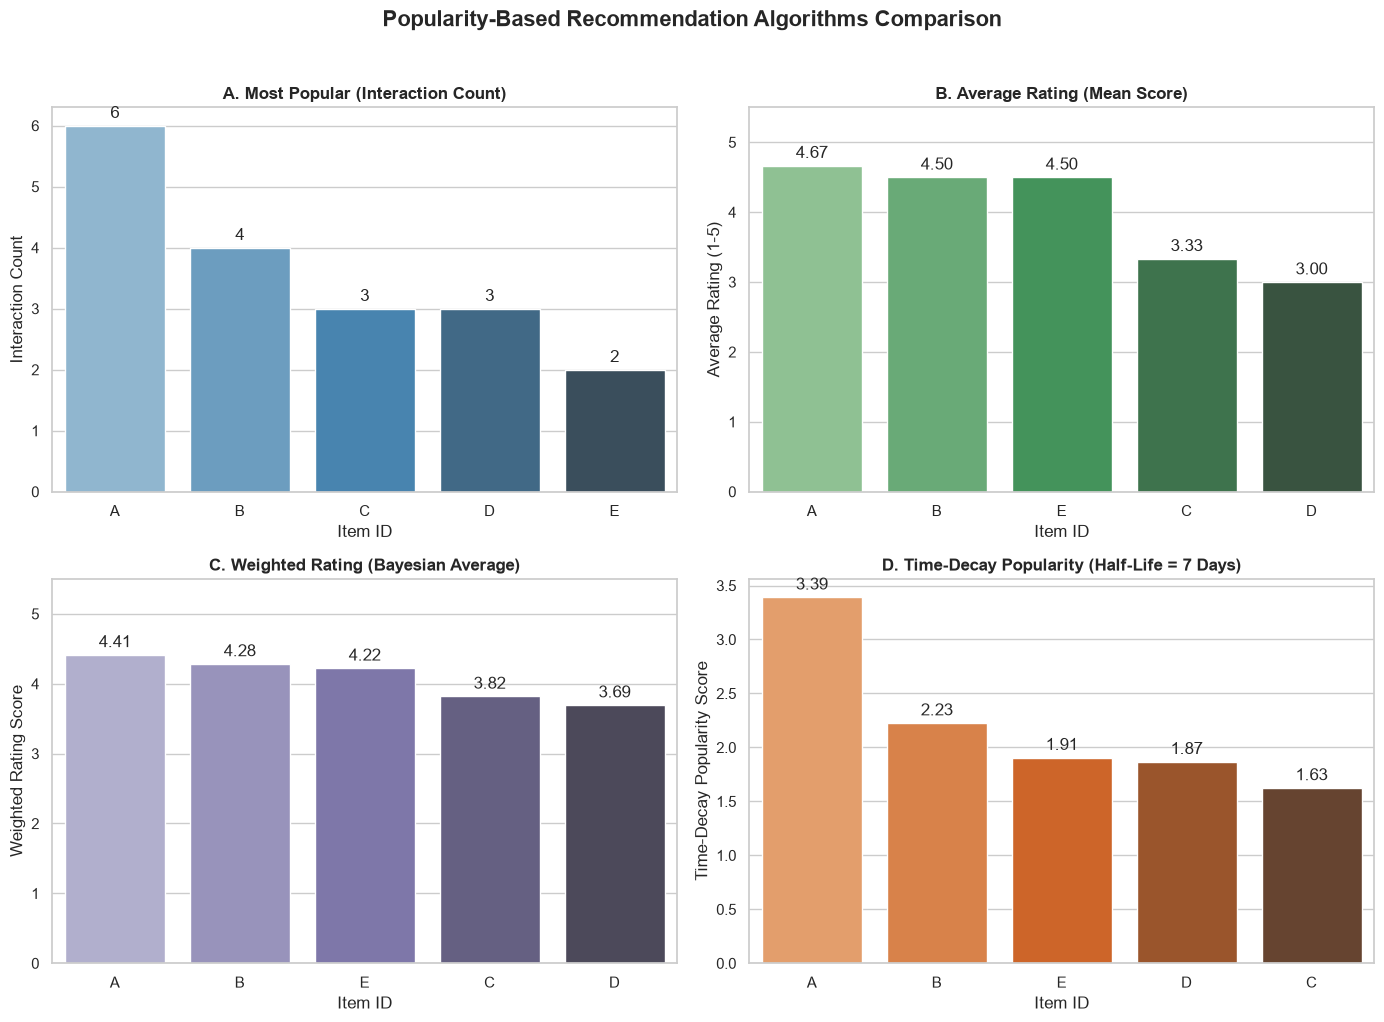

In [7]:
def plotPopularityComparison(df: pd.DataFrame) -> None:
  '''
  Membuat visualisasi grafik batang 2x2 untuk membandingkan hasil skor
  dari keempat algoritma rekomendasi berbasis popularitas.

  Args:
    df (pd.DataFrame): DataFrame interaksi pengguna yang memiliki kolom
      'itemId', 'rating', dan 'timestamp'.
  '''
  axes = None
  fig = None
  resAvg = averageRating(df)
  resDecay = timeDecayPopularity(df)
  resPopular = mostPopular(df)
  resWeighted = weightedRating(df)

  # Mengatur tema visualisasi seaborn
  sns.set_theme(style='whitegrid')

  # Membuat kanvas grafik 2x2 (axes adalah array 2D)
  fig, axes = plt.subplots(2, 2, figsize=(14, 10))
  fig.suptitle(
    'Popularity-Based Recommendation Algorithms Comparison',
    fontsize=16,
    fontweight='bold',
    y=1.02,
  )

  # 1. Grafik Most Popular -> indeks [0, 0]
  sns.barplot(
    ax=axes[0, 0],
    data=resPopular,
    hue='itemId',
    legend=False,
    palette='Blues_d',
    x='itemId',
    y='interactionCount',
  )
  axes[0, 0].set_title(
    'A. Most Popular (Interaction Count)',
    fontsize=12,
    fontweight='bold',
  )
  axes[0, 0].set_xlabel('Item ID')
  axes[0, 0].set_ylabel('Interaction Count')
  for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt='%d', padding=3)

  # 2. Grafik Average Rating -> indeks [0, 1]
  sns.barplot(
    ax=axes[0, 1],
    data=resAvg,
    hue='itemId',
    legend=False,
    palette='Greens_d',
    x='itemId',
    y='averageRating',
  )
  axes[0, 1].set_title(
    'B. Average Rating (Mean Score)',
    fontsize=12,
    fontweight='bold',
  )
  axes[0, 1].set_xlabel('Item ID')
  axes[0, 1].set_ylabel('Average Rating (1-5)')
  axes[0, 1].set_ylim(0, 5.5)
  for container in axes[0, 1].containers:
    axes[0, 1].bar_label(container, fmt='%.2f', padding=3)

  # 3. Grafik Weighted Rating -> indeks [1, 0]
  sns.barplot(
    ax=axes[1, 0],
    data=resWeighted,
    hue='itemId',
    legend=False,
    palette='Purples_d',
    x='itemId',
    y='weightedRating',
  )
  axes[1, 0].set_title(
    'C. Weighted Rating (Bayesian Average)',
    fontsize=12,
    fontweight='bold',
  )
  axes[1, 0].set_xlabel('Item ID')
  axes[1, 0].set_ylabel('Weighted Rating Score')
  axes[1, 0].set_ylim(0, 5.5)
  for container in axes[1, 0].containers:
    axes[1, 0].bar_label(container, fmt='%.2f', padding=3)

  # 4. Grafik Time-Decay Popularity -> indeks [1, 1]
  sns.barplot(
    ax=axes[1, 1],
    data=resDecay,
    hue='itemId',
    legend=False,
    palette='Oranges_d',
    x='itemId',
    y='popularityScore',
  )
  axes[1, 1].set_title(
    'D. Time-Decay Popularity (Half-Life = 7 Days)',
    fontsize=12,
    fontweight='bold',
  )
  axes[1, 1].set_xlabel('Item ID')
  axes[1, 1].set_ylabel('Time-Decay Popularity Score')
  for container in axes[1, 1].containers:
    axes[1, 1].bar_label(container, fmt='%.2f', padding=3)

  # Merapikan tata letak antar subplot dan menampilkan grafik
  plt.tight_layout()
  plt.show()


# Memanggil fungsi visualisasi
plotPopularityComparison(df)